# Chapitre 9 - Cours 1 : modèles additifs généralisés et backfitting

Le chapitre 9 de *The Elements of Statistical Learning* présente des méthodes qui
imposent une **structure** à la fonction de régression $f(x) = \mathbb E(Y\mid X=x)$
pour échapper au fléau de la dimension : modèles additifs, arbres, PRIM, MARS,
mélanges hiérarchiques d'experts. Ce premier notebook traite des **modèles additifs
généralisés** (section 9.1 du livre). Nous allons :

1. définir le modèle additif et ses variantes « généralisées » (fonctions de lien) ;
2. rappeler ce qu'est une **spline de lissage** et la notion de lisseur linéaire ;
3. établir et implémenter l'algorithme de **backfitting** (algorithme 9.1) ;
4. l'étendre à la régression logistique par le **local scoring** (algorithme 9.2) ;
5. reproduire l'analyse des **courriels spam** : table 9.1 et figure 9.1 du livre.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch09_arbres import (SplineLisseur, backfitting, GAM, logistic_irls,
                             SPAM_NAMES)

set_style()
rng = np.random.RandomState(0)

## 1. Le modèle additif

On observe une réponse $Y$ et $p$ prédicteurs $X_1,\dots,X_p$. Le modèle linéaire
suppose $\mathbb E(Y\mid X) = \alpha + \sum_j \beta_j X_j$ : l'effet de chaque variable
est une droite. Le **modèle additif** (éq. (9.1) du livre) remplace chaque droite par une
fonction quelconque (mais régulière) :
$$\mathbb E(Y\mid X_1,\dots,X_p) = \alpha + f_1(X_1) + f_2(X_2) + \dots + f_p(X_p).$$

> **Intuition.** On garde la grande force du modèle linéaire - **l'additivité** : l'effet
> de $X_j$ se lit sur un seul graphe $x_j \mapsto f_j(x_j)$, « toutes choses égales par
> ailleurs » - tout en autorisant des effets **non linéaires** (seuils, saturations…).
> En revanche, on renonce aux interactions : l'effet de $X_1$ ne dépend pas de la valeur
> de $X_2$.

**Pourquoi échappe-t-on au fléau de la dimension ?** Estimer une fonction générale de
$p$ variables demande un nombre d'observations qui explose avec $p$ (chapitre 2). Ici on
n'estime que $p$ fonctions **d'une seule variable** : chacune peut être estimée par un
lisseur unidimensionnel, comme au chapitre 5. Le prix à payer est un risque de **mauvaise
spécification** si la vraie fonction comporte des interactions.

### Modèles additifs *généralisés*

Pour une réponse binaire $Y\in\{0,1\}$, on note $\mu(X)=\Pr(Y=1\mid X)$. La régression
logistique (section 4.4) modélise le **logit** de $\mu$ par une fonction linéaire
(éq. (9.2)) ; le modèle additif logistique (éq. (9.3)) le remplace par une somme de
fonctions :
$$\log\frac{\mu(X)}{1-\mu(X)} = \alpha + f_1(X_1)+\dots+f_p(X_p).$$

Plus généralement (éq. (9.4)), on relie la moyenne conditionnelle $\mu(X)$ au
prédicteur additif par une **fonction de lien** $g$ :
$$g\big[\mu(X)\big] = \alpha + f_1(X_1) + \dots + f_p(X_p).$$
Liens classiques :

| lien | formule | usage |
|---|---|---|
| identité | $g(\mu)=\mu$ | réponse gaussienne |
| logit | $g(\mu)=\log\frac{\mu}{1-\mu}$ | réponse binaire |
| probit | $g(\mu)=\Phi^{-1}(\mu)$ | réponse binaire ($\Phi$ : f.d.r. de $\mathcal N(0,1)$) |
| log | $g(\mu)=\log \mu$ | comptages (loi de Poisson) |

> **Remarque.** Rien n'oblige toutes les $f_j$ à être non linéaires. On peut mélanger :
> des termes linéaires $X^T\beta$, des effets de facteurs qualitatifs $\alpha_k$, des
> fonctions $f(Z)$ non paramétriques, voire des fonctions de deux variables $g(Z,W)$ ou
> une courbe différente par modalité d'un facteur. Un exemple classique est la
> décomposition d'une série temporelle (éq. (9.5)) : $Y_t = S_t + T_t + \varepsilon_t$
> (saisonnalité + tendance + bruit).

## 2. Rappel : la spline de lissage, un lisseur linéaire

Pour une seule variable, la **spline de lissage cubique** (section 5.4) est la fonction
$f$ qui minimise
$$\sum_{i=1}^N \big(y_i - f(x_i)\big)^2 + \lambda \int f''(t)^2\,dt .$$
Le premier terme mesure l'ajustement, le second la **rugosité** (une droite a une
dérivée seconde nulle, donc une pénalité nulle). Le paramètre $\lambda\ge 0$ arbitre :
$\lambda=0$ interpole, $\lambda\to\infty$ donne la droite des moindres carrés.

On montre (chapitre 5) que la solution est une spline cubique naturelle à nœuds aux
$x_i$. En écrivant $f(x)=\sum_k c_k B_k(x)$ dans une base de splines, le critère devient
quadratique en $c$ :
$$\|y - Bc\|^2 + \lambda\, c^T\Omega c, \qquad \Omega_{kl}=\int B_k''(t)B_l''(t)\,dt,$$
d'où, en annulant le gradient, $\hat c = (B^TB+\lambda\Omega)^{-1}B^Ty$ et
$$\hat{\mathbf f} = B\hat c = \underbrace{B(B^TB+\lambda\Omega)^{-1}B^T}_{S_\lambda}\,y .$$

> **À retenir.** Le vecteur des valeurs ajustées est une fonction **linéaire** de $y$ :
> $\hat{\mathbf f}=S_\lambda y$. On dit que la spline de lissage est un **lisseur
> linéaire** et $S_\lambda$ est sa **matrice de lissage** ($N\times N$). Ses **degrés de
> liberté effectifs** sont $\mathrm{df}_\lambda=\mathrm{tr}(S_\lambda)$ : c'est une mesure
> de complexité plus parlante que $\lambda$.

Notre classe `SplineLisseur` (module `esl/ch09_arbres.py`) implémente ce calcul dans une
base de **B-splines cubiques** ; $\Omega$ est calculée exactement par quadrature. Avec un
nœud par valeur distincte de $x$ on obtient exactement la spline de lissage ; avec
quelques quantiles comme nœuds (option `n_knots`), on obtient une version pénalisée
beaucoup plus rapide, quasi identique en pratique. On peut demander directement un nombre
de degrés de liberté : $\lambda$ est alors trouvé par une recherche de racine.

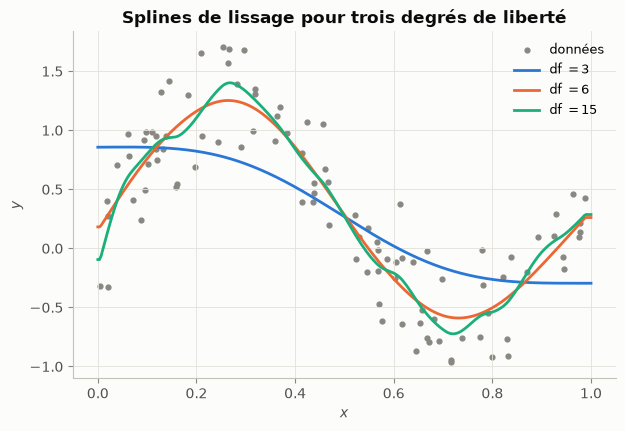

In [2]:
N = 100
x = np.sort(rng.uniform(0, 1, N))
f_vraie = np.sin(2 * np.pi * x) + 0.5 * x
y = f_vraie + 0.3 * rng.randn(N)

grille = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x, y, s=12, color=GRAY, label="données")
for k, df in enumerate([3, 6, 15]):
    sm = SplineLisseur(x, df=df)
    sm.fit(y)
    ax.plot(grille, sm.predict(grille), color=COLORS[k], label=r"df $=%d$" % df)
ax.set(title="Splines de lissage pour trois degrés de liberté",
       xlabel="$x$", ylabel="$y$")
ax.legend()
plt.show()

Vérifions numériquement les propriétés de $S_\lambda$ : symétrie, trace égale aux degrés
de liberté demandés, et valeurs propres dans $[0,1]$, deux d'entre elles valant
exactement 1 (les fonctions constantes et linéaires ne sont pas pénalisées, donc sont
reproduites telles quelles).

In [3]:
sm = SplineLisseur(x, df=6)
S = sm.matrix()
vp = np.sort(np.linalg.eigvalsh(S))[::-1]
print("symétrique :", np.allclose(S, S.T))
print("trace(S)   : %.4f" % np.trace(S))
print("6 plus grandes valeurs propres :", np.round(vp[:6], 4))
print("S @ (a + b x) = a + b x :", np.allclose(S @ (2 - 3 * x), 2 - 3 * x))

symétrique : True
trace(S)   : 6.0000
6 plus grandes valeurs propres : [1.     1.     0.9885 0.9157 0.7274 0.5158]
S @ (a + b x) = a + b x : True


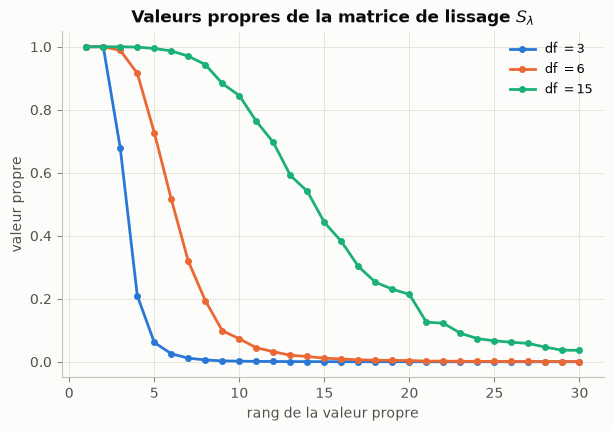

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for k, df in enumerate([3, 6, 15]):
    vp = np.sort(np.linalg.eigvalsh(SplineLisseur(x, df=df).matrix()))[::-1]
    ax.plot(np.arange(1, 31), vp[:30], "o-", ms=4, color=COLORS[k], label="df $=%d$" % df)
ax.set(title="Valeurs propres de la matrice de lissage $S_\\lambda$",
       xlabel="rang de la valeur propre", ylabel="valeur propre")
ax.legend()
plt.show()

La matrice $S_\lambda$ **rétrécit** chaque composante de $y$ dans sa base propre d'un
facteur compris entre 0 et 1 : les composantes lisses (premiers vecteurs propres) sont
conservées, les composantes oscillantes sont écrasées. C'est cette structure qui sera
exploitée dans les exercices 9.2 et 9.4.

## 3. Ajustement d'un modèle additif : le backfitting

### Le critère

Pour le modèle $Y = \alpha + \sum_j f_j(X_j) + \varepsilon$ (éq. (9.6)), on généralise
le critère de la spline de lissage en une **somme des carrés pénalisée** (éq. (9.7)) :
$$\mathrm{PRSS}(\alpha, f_1,\dots,f_p) = \sum_{i=1}^N\Big(y_i-\alpha-\sum_{j=1}^p
f_j(x_{ij})\Big)^2 + \sum_{j=1}^p \lambda_j\int f_j''(t_j)^2\,dt_j .$$

**Problème d'identifiabilité.** Si l'on ajoute une constante $c$ à $f_1$ et qu'on la
retranche à $\alpha$, la prédiction est inchangée : $\alpha$ et les $f_j$ ne sont pas
déterminés de façon unique. On impose donc la convention
$$\sum_{i=1}^N f_j(x_{ij}) = 0 \quad \text{pour tout } j,$$
(chaque fonction est **centrée** sur les données). Alors, en dérivant PRSS par rapport à
$\alpha$, on trouve $\hat\alpha = \frac1N\sum_i y_i = \bar y$.

On peut montrer que le minimiseur est une **spline cubique additive** : chaque $\hat f_j$
est une spline cubique en $x_j$ à nœuds aux valeurs $x_{ij}$. Si de plus la matrice des
entrées est de rang plein, le critère est strictement convexe et la solution est unique.

### L'idée du backfitting

Supposons toutes les fonctions connues **sauf** $f_j$. Le critère, vu comme fonction de
$f_j$ seule, s'écrit
$$\sum_i \big(r_{ij} - f_j(x_{ij})\big)^2 + \lambda_j \int f_j''^2,
\qquad r_{ij} = y_i - \hat\alpha - \sum_{k\neq j}\hat f_k(x_{ik}) ,$$
c'est exactement le critère d'une spline de lissage **unidimensionnelle** appliquée aux
**résidus partiels** $r_{ij}$. On sait donc minimiser en $f_j$ : $\hat f_j \leftarrow
S_j\, r_{\cdot j}$.

On minimise ainsi le critère **une fonction à la fois**, en cyclant sur $j$ : c'est une
descente par coordonnées (par blocs). Chaque étape ne peut que faire baisser PRSS, qui
est borné inférieurement par 0, d'où la convergence. On obtient l'**algorithme 9.1** :

1. *Initialisation* : $\hat\alpha = \frac1N\sum_i y_i$, $\hat f_j \equiv 0$ pour tout $j$.
2. *Cycle* $j = 1,2,\dots,p,1,2,\dots,p,\dots$ :
$$\hat f_j \leftarrow S_j\Big[\big\{y_i-\hat\alpha-\textstyle\sum_{k\ne j}\hat f_k(x_{ik})\big\}_{i=1}^N\Big],
\qquad \hat f_j \leftarrow \hat f_j - \frac1N\sum_{i=1}^N \hat f_j(x_{ij}),$$
   jusqu'à ce que les $\hat f_j$ varient moins qu'un seuil fixé.

> **Remarque.** La seconde ligne (recentrage) est en principe inutile pour une spline de
> lissage : lisser une réponse de moyenne nulle donne un ajustement de moyenne nulle
> (exercice 9.1). En pratique, les erreurs d'arrondi provoquent une lente « dérive » et le
> recentrage est conseillé. N'importe quel lisseur peut remplacer la spline : régression
> locale, noyaux, polynômes, splines de régression, lisseurs périodiques… Avec des
> lisseurs linéaires, le backfitting est un algorithme de **Gauss–Seidel** par blocs
> (exercice 9.2).

### Illustration sur données simulées

On simule $N=300$ observations d'un modèle additif à trois variables **corrélées**
(corrélation 0.5) : $f_1(x)=\sin(2x)$, $f_2(x)=x^2$ (centrée), $f_3(x)=0$ (variable
inutile), plus un bruit $\mathcal N(0, 0.5^2)$.

In [5]:
N = 300
C = 0.5 * np.ones((3, 3)) + 0.5 * np.eye(3)
Xs = rng.randn(N, 3) @ np.linalg.cholesky(C).T
vraies = [lambda t: np.sin(2 * t), lambda t: t ** 2 - 1, lambda t: 0 * t]
ys = 1.0 + sum(f(Xs[:, j]) for j, f in enumerate(vraies)) + 0.5 * rng.randn(N)
print("corrélations empiriques :\n", np.round(np.corrcoef(Xs.T), 2))

corrélations empiriques :
 [[1.   0.42 0.53]
 [0.42 1.   0.45]
 [0.53 0.45 1.  ]]


On place une spline de lissage à 4 degrés de liberté nominaux sur chaque variable. Le
livre définit les degrés de liberté d'un terme par $\mathrm{df}_j=\mathrm{tr}(S_j)-1$ :
on retranche 1 car la constante est déjà prise en charge par $\alpha$.

In [6]:
lisseurs = [SplineLisseur(Xs[:, j], df=5.0, n_knots=20) for j in range(3)]
alpha, F, n_iter, rss = backfitting(ys, lisseurs, tol=1e-8, history=True)
print("alpha chapeau = %.4f   (moyenne de y = %.4f)" % (alpha, ys.mean()))
print("nombre de cycles :", n_iter)
print("moyennes des f_j :", np.round(F.mean(0), 12))

alpha chapeau = 0.9821   (moyenne de y = 0.9821)
nombre de cycles : 17
moyennes des f_j : [ 0. -0. -0.]


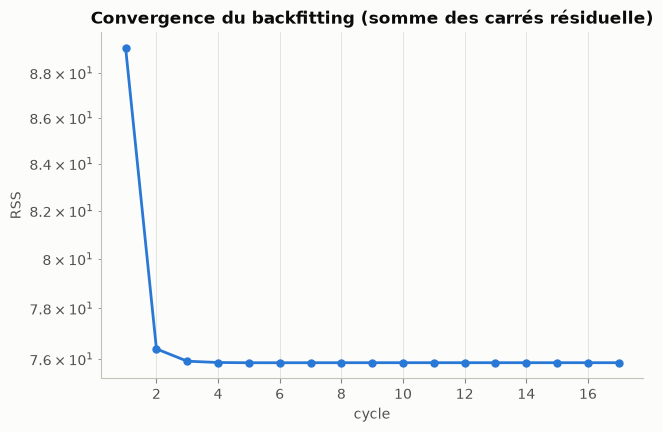

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, len(rss) + 1), rss, "o-", color=BLUE)
ax.set(title="Convergence du backfitting (somme des carrés résiduelle)",
       xlabel="cycle", ylabel="RSS", yscale="log")
plt.show()

La convergence est très rapide : quelques cycles suffisent (le livre indique
« généralement moins de 20 et souvent moins de 10 », section 9.7). Elle est d'autant
plus lente que les variables sont corrélées.

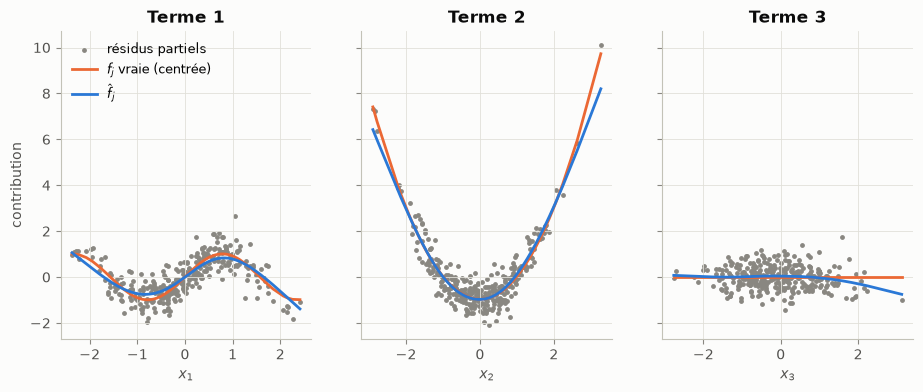

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
for j, ax in enumerate(axes):
    o = np.argsort(Xs[:, j])
    vrai = vraies[j](Xs[o, j])
    ax.scatter(Xs[:, j], F[:, j] + (ys - alpha - F.sum(1)), s=6, color=GRAY,
               label="résidus partiels")
    ax.plot(Xs[o, j], vrai - vrai.mean(), color=ORANGE, label="$f_j$ vraie (centrée)")
    ax.plot(Xs[o, j], F[o, j], color=BLUE, label=r"$\hat f_j$")
    ax.set(title="Terme %d" % (j + 1), xlabel="$x_%d$" % (j + 1))
axes[0].set_ylabel("contribution")
axes[0].legend(loc="upper left")
plt.show()

Les trois fonctions sont bien retrouvées, y compris la fonction nulle de la variable 3,
**malgré la corrélation** entre prédicteurs : le backfitting « ajuste » chaque effet des
autres, exactement comme la régression multiple ajuste chaque coefficient des autres
variables. Un lissage séparé de $y$ contre chaque $x_j$ donnerait au contraire des effets
**marginaux** biaisés :

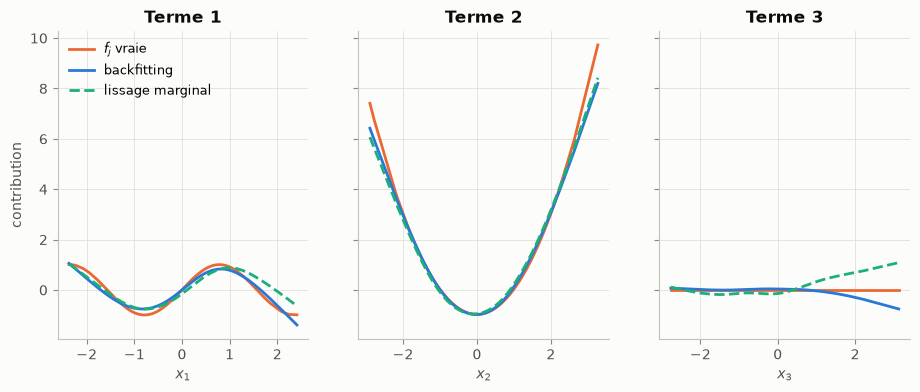

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
for j, ax in enumerate(axes):
    o = np.argsort(Xs[:, j])
    marg = SplineLisseur(Xs[:, j], df=5.0, n_knots=20).fit(ys - ys.mean())
    vrai = vraies[j](Xs[o, j])
    ax.plot(Xs[o, j], vrai - vrai.mean(), color=ORANGE, label="$f_j$ vraie")
    ax.plot(Xs[o, j], F[o, j], color=BLUE, label="backfitting")
    ax.plot(Xs[o, j], marg[o], color=COLORS[2], ls="--", label="lissage marginal")
    ax.set(title="Terme %d" % (j + 1), xlabel="$x_%d$" % (j + 1))
axes[0].set_ylabel("contribution")
axes[0].legend(loc="upper left")
plt.show()

> **À retenir.** Le backfitting ajuste un modèle additif en lissant **itérativement les
> résidus partiels** contre chaque variable. C'est l'analogue non paramétrique de la
> régression multiple : chaque $\hat f_j$ est un effet « toutes choses égales par
> ailleurs ». Le degré de lissage de chaque terme se règle par $\mathrm{df}_j =
> \mathrm{tr}(S_j)-1$ ($\mathrm{df}_j=1$ correspond à un terme linéaire).

## 4. Modèle additif logistique : le *local scoring*

### Rappel : Newton–Raphson pour la régression logistique (section 4.4.1)

Pour $y_i\in\{0,1\}$ et $\eta_i = \alpha + x_i^T\beta$, $p_i = 1/(1+e^{-\eta_i})$, la
log-vraisemblance est $\ell = \sum_i [y_i\eta_i - \log(1+e^{\eta_i})]$. Un pas de
Newton–Raphson s'écrit comme une **régression linéaire pondérée** de la *réponse de
travail*
$$z_i = \eta_i + \frac{y_i - p_i}{p_i(1-p_i)}$$
sur les $x_i$, avec les poids $w_i = p_i(1-p_i)$. On itère : c'est l'algorithme IRLS
(moindres carrés itérativement repondérés).

**D'où vient $z_i$ ?** On développe $\ell$ au second ordre autour de $\eta$ : le gradient
par rapport à $\eta_i$ vaut $y_i - p_i$ et la dérivée seconde $-p_i(1-p_i)$. Donc
$$\ell(\eta+\delta) \approx \ell(\eta) + \sum_i (y_i-p_i)\delta_i - \frac12\sum_i
p_i(1-p_i)\delta_i^2 = \text{cste} - \frac12\sum_i w_i\Big(\frac{y_i-p_i}{w_i} -
\delta_i\Big)^2 .$$
Maximiser cette approximation en $\eta^{\text{nouv}} = \eta + \delta$ revient à minimiser
$\sum_i w_i (z_i - \eta^{\text{nouv}}_i)^2$ : des moindres carrés pondérés de $z$.

### L'algorithme 9.2

Dans le modèle additif, $\eta_i = \alpha + \sum_j f_j(x_{ij})$ : il suffit de remplacer la
régression linéaire pondérée par un **backfitting pondéré** (chaque lisseur accepte des
poids $w_i$).

1. Initialisation : $\hat\alpha = \log[\bar y/(1-\bar y)]$, $\hat f_j\equiv 0$.
2. Itérer : $\hat\eta_i = \hat\alpha + \sum_j\hat f_j(x_{ij})$, $\hat p_i =
   1/(1+e^{-\hat\eta_i})$ ;
   (a) réponse de travail $z_i = \hat\eta_i + (y_i-\hat p_i)/[\hat p_i(1-\hat p_i)]$ ;
   (b) poids $w_i = \hat p_i(1-\hat p_i)$ ;
   (c) backfitting pondéré de $z$ avec les poids $w$ → nouveaux $\hat\alpha$, $\hat f_j$.
3. Arrêt quand les fonctions (ou la déviance) ne bougent plus.

La classe `GAM(family="binomial")` du module implémente cet algorithme. Pour que
$\lambda_j$ garde le même sens d'une itération à l'autre, nous normalisons les poids pour
qu'ils soient de moyenne 1 ; les $\lambda_j$ sont fixés une fois pour toutes, de sorte
que $\mathrm{tr}(S_j)-1$ vaille le nombre de degrés de liberté nominal **à poids égaux**.

## 5. Exemple : détection des courriels spam

Les données (chapitre 1) décrivent 4601 courriels par 57 variables : 48 fréquences de
mots (en % des mots du message : *business*, *free*, *george*…), 6 fréquences de
caractères (`ch;`, `ch(`, `ch[`, `ch!`, `ch$`, `ch#`) et trois statistiques sur les
suites de majuscules : longueur moyenne `CAPAVE`, maximale `CAPMAX`, totale `CAPTOT`.
La réponse vaut 1 pour un spam, 0 pour un courriel normal.

In [10]:
spam = datasets.load_spam()
X = spam.drop(columns="spam").to_numpy(float)
y = spam["spam"].to_numpy()
print("dimensions :", X.shape, "  proportion de spam : %.3f" % y.mean())
print(SPAM_NAMES[:10], "...", SPAM_NAMES[-3:])

dimensions : (4601, 57)   proportion de spam : 0.394
['make', 'address', 'all', '3d', 'our', 'over', 'remove', 'internet', 'order', 'mail'] ... ['CAPAVE', 'CAPMAX', 'CAPTOT']
